## ReLU MLP Single-Seed Learning Dynamics

This notebook runs a standard fully connected ReLU network with a single training phase.

It focuses on one seed to inspect learning dynamics clearly (checkpoints, scatter alignment, and start/end metrics).

No dropout, normalization, or multi-phase logic is used.

In [1]:
from pathlib import Path

from itables import show
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from itertools import product

%load_ext autoreload
%autoreload 2

from layer_lenses.odt import samples_reaching_node
from layer_lenses.odt import odt_leaf_ids_for_x
from layer_lenses.relu_analysis import (
    collect_start_end_metrics,
    first_layer_odt_alignment,
    masked_accuracy_by_odt_leaf,
    neuron_leaf_responsibility_from_ablation,
    plot_first_layer_odt_alignment,
    plot_layered_relu_graph,
    quadratic_snapshot_epochs,
    run_single_relu_seed,
    summarize_neuron_responsibility,
)
from layer_lenses.relu_analysis import log_loss_gradients
from layer_lenses.relu_training import checkpoint_model_from_state
from layer_lenses.relu_analysis import activation_tensor_by_layer_neuron_data

from pathlib import Path
import pickle
from typing import Any

def save_seed_result_pickle(seed_result: dict[str, Any], path: str | Path) -> Path:
    """Save seed_result to a pickle file."""
    out_path = Path(path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with out_path.open("wb") as f:
        pickle.dump(seed_result, f, protocol=pickle.HIGHEST_PROTOCOL)
    return out_path


def load_seed_result_pickle(path: str | Path) -> dict[str, Any]:
    """Load seed_result from a pickle file."""
    in_path = Path(path)
    with in_path.open("rb") as f:
        obj = pickle.load(f)
    if not isinstance(obj, dict):
        raise TypeError(f"Expected dict from pickle, got {type(obj).__name__}")
    return obj


In [15]:


# Scratch-aligned defaults with a plain ReLU MLP.
DIM = 100
DEPTH = 5
N_TRAIN = 1_000_000
HIDDEN_DIMS = [40,40,40]

TOTAL_EPOCHS = 1_000_000
LR = 2e-3
BATCH_SIZE = 1_000_000
WEIGHT_DECAY = 0.01
MOMENTUM = 0.9
SNAPSHOT_EPOCHS = list[int](range(0,100)) + list[int](range(100,TOTAL_EPOCHS,5000))
print(f"Using {len(SNAPSHOT_EPOCHS)} snapshot epochs.")

SEED = 5178

seed_result = None

Using 300 snapshot epochs.


## Run selected seed

This is the expensive cell. It runs single-phase ReLU MLP training for the selected seed.

In [16]:
print(f"Running seed {SEED} ...")
seed_result = run_single_relu_seed(
    SEED,
    dim=DIM,
    depth=DEPTH,
    n_train=N_TRAIN,
    hidden_dims=HIDDEN_DIMS,
    total_epochs=TOTAL_EPOCHS,
    lr=LR,
    momentum=MOMENTUM,
    batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY,
    snapshot_epochs=SNAPSHOT_EPOCHS,
    project_first_layer_grad_orthogonal=None,
    odt_hyperplanes = "random_orthogonal",
    bias= False,
    optimizer="adam",
    device="cuda"
)
print("Done")

Running seed 5178 ...


Training ReLU MLP:   0%|          | 0/1000001 [00:00<?, ?it/s]

Done


In [26]:


# Save
# save_path = save_seed_result_pickle(seed_result, "results/cache/seed_result_5178_5_40_40_40_1Mtrain_1Mbatch_adam_randomhyper_Sep7.pkl")
# print("Saved to:", save_path)

# Load
seed_result = load_seed_result_pickle("results/cache/seed_result_5178_5_40_40_40_1Mtrain_10kbatch_adam_randomhyper.pkl")
print(seed_result.keys()) 

dict_keys(['master_seed', 'seeds', 'tree', 'meta', 'data', 'out'])


In [27]:
seed_result["data"]["x_train"].shape

(1000000, 100)

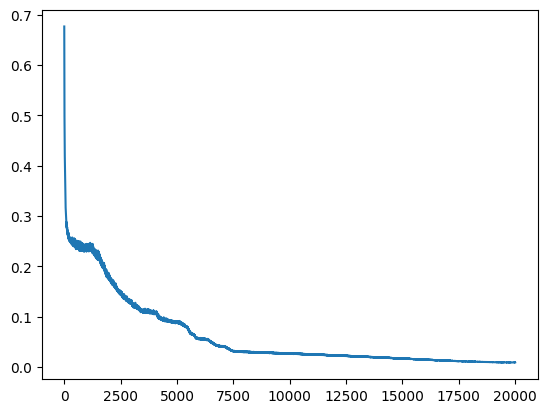

In [28]:
plt.plot(seed_result["out"]["epoch_losses"][0:])
out = seed_result["out"]
ckpts = out["checkpoint_snapshots"]
tree = seed_result["tree"]

## Neuron-wise First layer neuron alignment analysis

In [29]:
for name, param in ckpts[19900].items():
    print(name, param.shape)

hidden_layers.0.weight torch.Size([40, 100])
hidden_layers.1.weight torch.Size([40, 40])
hidden_layers.2.weight torch.Size([40, 40])
output_layer.weight torch.Size([1, 40])


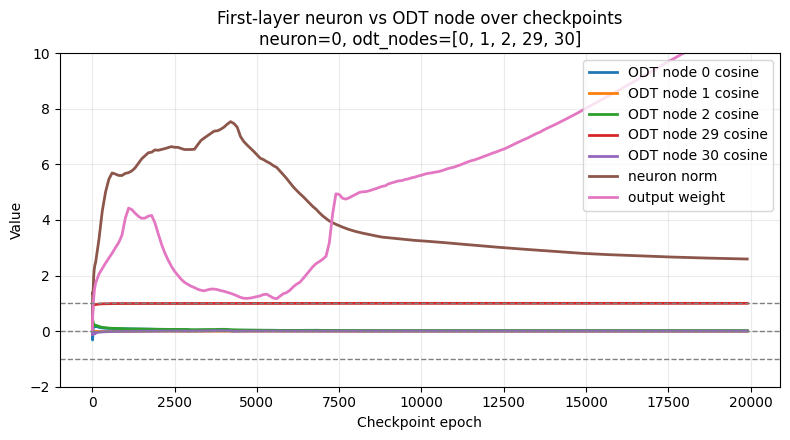

In [31]:
FIRST_LAYER_NEURON_ID = [0]
ODT_INTERNAL_NODE_ID = [0,1,2,29,30]
START_EPOCH_PLOT_IDX = 0
END_EPOCH_PLOT_IDX = 300



neuron_ids = list(FIRST_LAYER_NEURON_ID)
odt_node_ids = list(ODT_INTERNAL_NODE_ID)

if not neuron_ids:
    raise ValueError("FIRST_LAYER_NEURON_ID must not be empty.")
if not odt_node_ids:
    raise ValueError("ODT_INTERNAL_NODE_ID must not be empty.")

first_layer_width = ckpts[0]["hidden_layers.0.weight"].shape[0]
internal_node_count = tree.w_list.shape[0]

for neuron_id in neuron_ids:
    if not (0 <= neuron_id < first_layer_width):
        raise ValueError(
            f"Each FIRST_LAYER_NEURON_ID must be in [0, {first_layer_width - 1}], "
            f"got {neuron_id}."
        )

for odt_node_id in odt_node_ids:
    if not (0 <= odt_node_id < internal_node_count):
        raise ValueError(
            f"Each ODT_INTERNAL_NODE_ID must be in [0, {internal_node_count - 1}], "
            f"got {odt_node_id}."
        )

epochs = sorted(ckpts.keys())[START_EPOCH_PLOT_IDX:END_EPOCH_PLOT_IDX]

odt_vectors = {
    odt_node_id: torch.from_numpy(tree.w_list[odt_node_id]).float()
    for odt_node_id in odt_node_ids
}
odt_norms = {
    odt_node_id: float(torch.norm(vector).clamp_min(1e-12))
    for odt_node_id, vector in odt_vectors.items()
}

fig, axes = plt.subplots(
    nrows=len(neuron_ids),
    ncols=1,
    figsize=(8, 4.5 * len(neuron_ids)),
    sharex=True,
    squeeze=False,
)
axes = axes[:, 0]

for ax, neuron_id in zip(axes, neuron_ids):
    neuron_norms = []
    output_wts = []
    normalized_inner_products = {
        odt_node_id: [] for odt_node_id in odt_node_ids
    }

    for epoch in epochs:
        w = (
            ckpts[epoch]["hidden_layers.0.weight"][neuron_id]
            .detach()
            .cpu()
            .float()
        )
        w_norm = float(torch.norm(w).clamp_min(1e-12))
        neuron_norms.append(w_norm)
        output_wts.append(ckpts[epoch]["output_layer.weight"][0,neuron_id].detach().cpu().float())
        for odt_node_id in odt_node_ids:
            cosine = float(
                torch.dot(w, odt_vectors[odt_node_id])
                / (w_norm * odt_norms[odt_node_id])
            )
            normalized_inner_products[odt_node_id].append(cosine)

    for odt_node_id in odt_node_ids:
        label = (
            "normalized inner product (cosine)"
            if len(odt_node_ids) == 1
            else f"ODT node {odt_node_id} cosine"
        )
        ax.plot(
            epochs,
            normalized_inner_products[odt_node_id],
            linewidth=2.0,
            label=label,
        )

    ax.plot(
        epochs,
        neuron_norms,
        linewidth=2.0,
        label="neuron norm",
    )
    ax.plot(
        epochs,
        output_wts,
        linewidth=2.0,
        label="output weight",
    )
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(-1.0, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Value")
    # ax.set_yscale("log")
    ax.set_title(
        "First-layer neuron vs ODT node over checkpoints\n"
        f"neuron={neuron_id}, odt_nodes={odt_node_ids}"
    )
    ax.set_ylim(-2,10)
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Checkpoint epoch")
fig.tight_layout()
plt.show()

## Scatter plot  

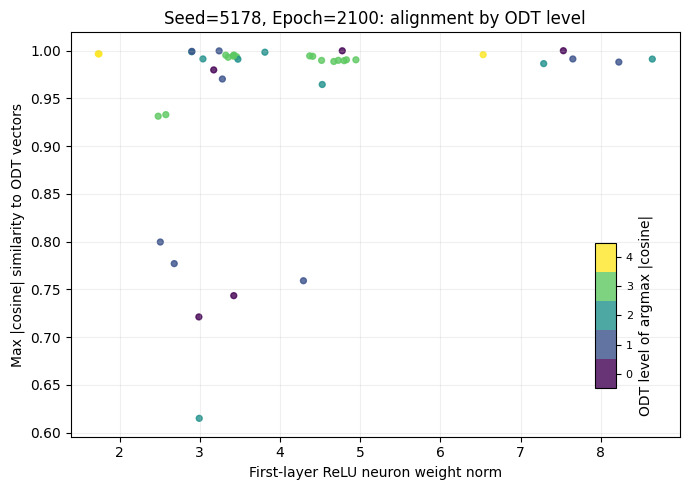

In [36]:
EPOCH = list(ckpts.keys())[120]  # choose from available checkpoints

alignment, fig, ax = plot_first_layer_odt_alignment(
    state_dict=ckpts[EPOCH],
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    seed=SEED,
)
plt.show()

# Keep these names available for downstream scratch cells.
first_layer_wts = alignment["first_layer_wts"]
odt_wts = alignment["odt_wts"]
row_norms = alignment["row_norms"]
cos = alignment["cos"]
abs_cos = alignment["abs_cos"]
max_abs_cos = alignment["max_abs_cos"]
closest_odt = alignment["closest_odt"]
closest_odt_np = alignment["closest_odt_np"]
node_level = alignment["node_level"]

state = ckpts[EPOCH]
HIDDEN_WEIGHTS = [
    state[f"hidden_layers.{layer_idx}.weight"].detach().cpu()
    for layer_idx in range(len(HIDDEN_DIMS))
]
W0 = HIDDEN_WEIGHTS[0]
Wout = state["output_layer.weight"].detach().cpu()



## neuron merge analysis

In [ ]:
W = ckpts[EPOCH]["hidden_layers.0.weight"]   # (150, 100)
v = ckpts[EPOCH]["output_layer.weight"][0]   # (150,)
u0 = torch.as_tensor(tree.w_list[0], dtype=W.dtype)
u0 = u0 / u0.norm()

w = W[[69, 114]]
p = v[[69, 114]] * torch.linalg.vector_norm(w, dim=1)  # signed products
align = (w @ u0) 
orth = torch.linalg.vector_norm(w - align[:, None] * u0, dim=1)
cos_pair = torch.nn.functional.cosine_similarity(w[0], w[1], dim=0)

In [ ]:
def merge_pair(state, i=69, j=114, ODT_wts):
    s = {k: t.clone() for k, t in state.items()}
    w, v = s["hidden_layers.0.weight"], s["output_layer.weight"] 
    # the two w vectors will be positive scalar multiples of each other. The v scalars are opposite in sign. In the defauult example w_i and w_j are along u_0
    
    # collapse j into i in function space, then zero j
    p_i = w[i] / w[i].norm()
    p_j = w[j]/w[j].norm()          # same gate ⇒ products add
    p = p_i + p_j
    p = p / p.norm()
    # simpler: put the net map on i, kill j
    v[0, i] = v[0, i]*w[i].norm() + v[0, j]*w[j].norm()
    w[i] = p
    
    w[j] = 0
    v[0, j] = 0
    return s

In [ ]:
merged_ckpt = merge_pair(ckpts[EPOCH], ODT_wts=odt_wts)
print(merged_ckpt["hidden_layers.0.weight"][69].norm())
print(merged_ckpt["hidden_layers.0.weight"][114].norm())
print(merged_ckpt["output_layer.weight"][0,69])
print(merged_ckpt["output_layer.weight"][0,114])

print(ckpts[EPOCH]["hidden_layers.0.weight"][69].norm())
print(ckpts[EPOCH]["hidden_layers.0.weight"][114].norm())
print(ckpts[EPOCH]["output_layer.weight"][0,69])
print(ckpts[EPOCH]["output_layer.weight"][0,114])



In [ ]:
from layer_lenses.relu_training import evaluate_relu_mlp
model1 = checkpoint_model_from_state(seed_result["out"]["model"], ckpts[EPOCH])
model2 = checkpoint_model_from_state(seed_result["out"]["model"], merged_ckpt)

results_pre_merge = evaluate_relu_mlp(model=model1, x_eval=seed_result["data"]["x_train"], y_eval=seed_result["data"]["y_train"], device="cuda")
results_post_merge = evaluate_relu_mlp(model=model2, x_eval=seed_result["data"]["x_train"], y_eval=seed_result["data"]["y_train"], device="cuda")

print(results_pre_merge["log_loss"])
print(results_post_merge["log_loss"])



## Load hidden-layer and output parameters from a given epoch

In [37]:
components = torch.diag(row_norms) @ cos
max_w, argmax_w = torch.max(cos.abs(), dim=0)
for input_idx in range(components.shape[1]):
    neuron_idx = int(argmax_w[input_idx])
    print(
        input_idx,
        max_w[input_idx],
        argmax_w[input_idx],
        components[neuron_idx].norm(),
    )


0 tensor(1.0000) tensor(30) tensor(7.5335)
1 tensor(0.9998) tensor(12) tensor(3.2410)
2 tensor(0.9913) tensor(6) tensor(7.6513)
3 tensor(0.9984) tensor(7) tensor(3.8114)
4 tensor(0.9989) tensor(5) tensor(2.8987)
5 tensor(0.9911) tensor(15) tensor(3.4747)
6 tensor(0.9914) tensor(18) tensor(3.0389)
7 tensor(0.9944) tensor(21) tensor(3.4154)
8 tensor(0.9945) tensor(27) tensor(4.3703)
9 tensor(0.9953) tensor(14) tensor(3.3232)
10 tensor(0.9955) tensor(20) tensor(3.4258)
11 tensor(0.9330) tensor(1) tensor(2.5759)
12 tensor(0.9905) tensor(2) tensor(4.8284)
13 tensor(0.9899) tensor(13) tensor(4.7271)
14 tensor(0.9904) tensor(25) tensor(4.9461)
15 tensor(0.0806) tensor(4) tensor(3.4604)
16 tensor(0.1583) tensor(29) tensor(2.5070)
17 tensor(0.2812) tensor(28) tensor(2.9884)
18 tensor(0.0850) tensor(27) tensor(4.3703)
19 tensor(0.4351) tensor(8) tensor(2.9929)
20 tensor(0.1024) tensor(36) tensor(3.3530)
21 tensor(0.9967) tensor(10) tensor(1.7333)
22 tensor(0.0823) tensor(35) tensor(3.4245)
23 te

## Visualise neural net as graph

Visible edges: 2643 / 3240
First-layer aligned nodes: 34 / 40


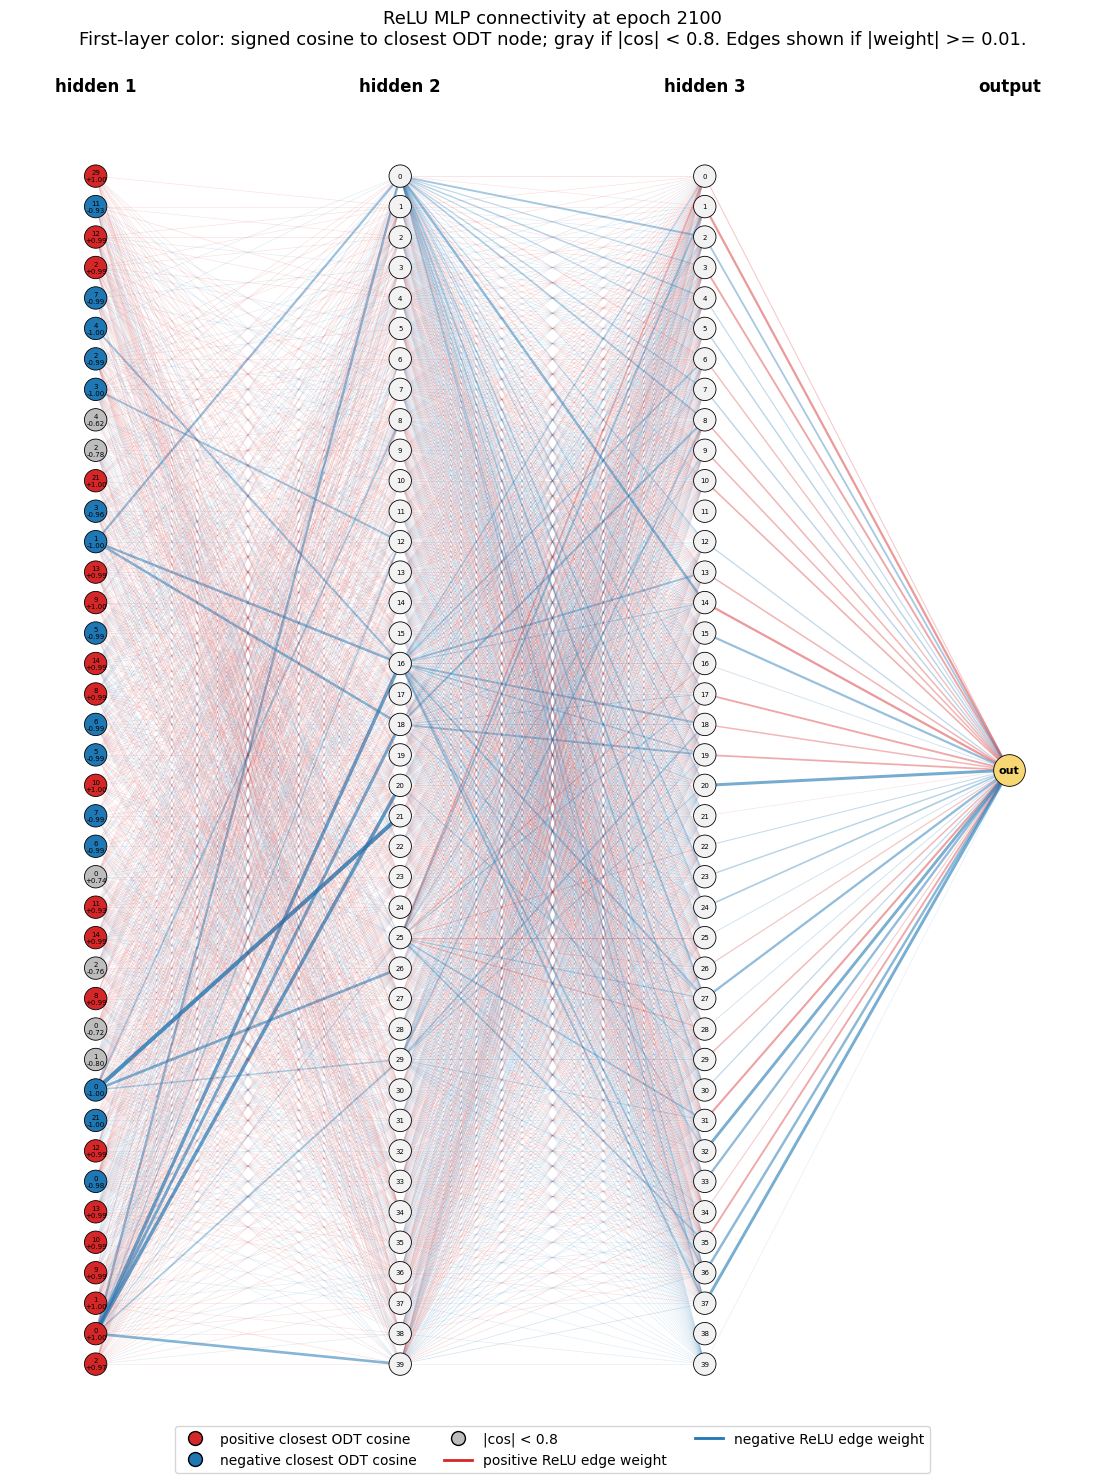

In [38]:
# Layered ReLU graph at a chosen snapshot epoch.
ALIGNMENT_ABS_THRESHOLD = 0.8
EDGE_ABS_THRESHOLD = 0.01  # tune this; increase if graph is too dense
FIGSIZE = (14, 18)

# One mask per hidden layer; edit individual entries to select nodes.
NODE_MASK = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]

graph_alignment, visible_edges, graph_fig, graph_ax = plot_layered_relu_graph(
    state_dict=state,
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    node_mask=NODE_MASK,
    alignment_abs_threshold=ALIGNMENT_ABS_THRESHOLD,
    edge_abs_threshold=EDGE_ABS_THRESHOLD,
    figsize=FIGSIZE,
    require_both_edge_endpoints_selected=True,
)
plt.show()

In [13]:
odt_node = 29
large_alignment_ids = torch.where((components[:,odt_node]/components.norm(dim=1)).abs()>0.8)[0]

for neuron_id in large_alignment_ids:
    print(neuron_id,"\t",components[neuron_id,odt_node],"\t",components[neuron_id].norm(),"\t",Wout[0,neuron_id])


NameError: name 'components' is not defined

## Computing neuron responsibilities -- i.e. log loss changes to data entering leaf nodes on neuron removal

In [11]:
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    ckpts[EPOCH],
)
base_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]


In [19]:

neuron_responsibility, neuron_responsibility_df, baseline_leaf_metrics = (
    neuron_leaf_responsibility_from_ablation(
        model=checkpoint_model,
        x_eval=seed_result["data"]["x_train"],
        y_eval=seed_result["data"]["y_train"],
        tree=seed_result["tree"],
        base_node_mask=base_node_mask,
        min_log_loss_delta=-2.,
        min_relative_log_loss_delta=None,
        min_accuracy_drop=None,
    )
)
neuron_summary = summarize_neuron_responsibility(neuron_responsibility)


In [20]:
baseline_leaf_metrics

,leaf_node,leaf_index,true_label,num_samples,num_correct,baseline_accuracy,baseline_mean_log_loss,baseline_mean_logit,baseline_mean_abs_logit
0,31,0,-1,31174,29089,0.933117,0.212420,-2.892813,3.026892
1,32,1,1,31078,27539,0.886125,0.281303,2.682488,2.893498
2,33,2,-1,31220,29375,0.940903,0.206813,-2.885322,3.005960
3,34,3,1,31123,27642,0.888153,0.282072,2.603822,2.808968
4,35,4,-1,31444,29503,0.938271,0.204811,-3.224137,3.369298
5,36,5,1,31507,28681,0.910306,0.243995,3.054902,3.232729
6,37,6,-1,31492,29157,0.925854,0.212589,-3.339329,3.501868
7,38,7,1,31325,28591,0.912721,0.237637,3.247541,3.436021
8,39,8,-1,31417,29662,0.944139,0.192491,-3.354124,3.483502
9,40,9,1,31412,27829,0.885935,0.283719,2.685935,2.902341


In [22]:
layer_select = 0
neuron_select = 30

show(
    neuron_responsibility_df[(neuron_responsibility_df["layer"]==layer_select) & (neuron_responsibility_df["neuron_id"]==neuron_select) ],
    scrollY="500px",
    scrollX=True,
    search=True,
    paging=True,
    pageLength=32,
)

Loading ITables v2.7.3 from the internet... (need help?)


In [ ]:
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    ckpts[EPOCH],
)

# Keep only selected neurons in one layer while retaining every other layer.
MASKED_LAYER_IDX = 0
MASKED_NEURON_IDS = 94
node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
node_mask[MASKED_LAYER_IDX][:] = False
node_mask[MASKED_LAYER_IDX][MASKED_NEURON_IDS] = True

leaf_accuracy = masked_accuracy_by_odt_leaf(
    model=checkpoint_model,
    node_mask=node_mask,
    x_eval=seed_result["data"]["x_eval"],
    y_eval=seed_result["data"]["y_eval"],
    tree=seed_result["tree"],
)

display(leaf_accuracy)
print(
    "Overall masked accuracy:",
    np.average(
        leaf_accuracy["accuracy"],
        weights=leaf_accuracy["num_samples"],
    ),
)

## Neuron activity breakdown -- neuron activity based on data entering ODT leaf nodes 

In [64]:

checkpoint_model = checkpoint_model_from_state(seed_result["out"]["model"], ckpts[EPOCH])

acts = activation_tensor_by_layer_neuron_data(
    model=checkpoint_model,
    x_eval=seed_result["data"]["x_train"],
)
outputs = checkpoint_model(torch.tensor(seed_result["data"]["x_train"], dtype=torch.float32)).detach().cpu().numpy()
labels = seed_result["data"]["y_train"]

residues = np.exp(-labels*outputs)/(1+np.exp(-labels*outputs))
leaf_ids = odt_leaf_ids_for_x(seed_result["data"]["x_train"], seed_result["tree"])

print("activation_tensor shape:", acts.shape)  # (layers, neurons, num_data)
print("Residues shape:", residues.shape)


activation_tensor shape: (3, 40, 100000)
Residues shape: (100000,)


In [ ]:
# from itertools import product
# layer0 = range(HIDDEN_DIMS[0])
# layer1 = range(HIDDEN_DIMS[1])
# layer2 = range(HIDDEN_DIMS[2])
# path_stats = dict()
# for path in product(layer0,layer1,layer2):
#     print(path)
#     acts_path = acts[0,path[0]]*acts[1,path[1]]*acts[2,path[2]]
#     weight_path = (HIDDEN_WEIGHTS[1][path[1],path[0]]*HIDDEN_WEIGHTS[2][path[2],path[1]]*Wout[0,path[2]]).numpy()*np.linalg.norm(W0[path[0]].numpy())
#     acts_path_hist = np.array([np.sum(acts_path[leaf_ids==j]) for j in range(31,63)])
#     first_layer_gating_vec = W0[path[0]].numpy()/np.linalg.norm(W0[path[0]].numpy())
#     path_stats[path] = dict(
#         weight=weight_path,
#         acts_hist=acts_path_hist,
#         first_layer_gating_vec=first_layer_gating_vec,
#     )

# for path in path_stats:
#     path_stats[path]["num_points"] = np.sum(path_stats[path]["acts_hist"])


In [18]:
n0, n1, n2 = (int(w) for w in HIDDEN_DIMS[:3])
leaf_values = np.arange(31, 63)
n_leaves = leaf_values.size
n_data = acts.shape[-1]

A0 = np.ascontiguousarray(acts[0, :n0], dtype=np.float32)
A1 = np.ascontiguousarray(acts[1, :n1], dtype=np.float32)
A2 = np.ascontiguousarray(acts[2, :n2], dtype=np.float32)
leaf_ids_arr = np.asarray(leaf_ids)

W1 = HIDDEN_WEIGHTS[1][:n1, :n0].detach().cpu().numpy()
W2 = HIDDEN_WEIGHTS[2][:n2, :n1].detach().cpu().numpy()
wout = Wout[0, :n2].detach().cpu().numpy()
W0_np = W0[:n0].detach().cpu().numpy()
w0_norm = np.linalg.norm(W0_np, axis=1)
gating = W0_np / w0_norm[:, None]

# weight[i, j, k] = W1[j, i] * W2[k, j] * Wout[k] * ||W0[i]||
weights = np.einsum("ji,kj,k,i->ijk", W1, W2, wout, w0_norm)

# hist[i, j, k, leaf] = number of points in that leaf on path (i, j, k)
hist = np.zeros((n0, n1, n2, n_leaves), dtype=np.float32)
for leaf_pos, leaf in enumerate(leaf_values):
    idx = np.flatnonzero(leaf_ids_arr == leaf)
    if idx.size == 0:
        continue
    a0 = A0[:, idx]
    a1 = A1[:, idx]
    a2 = A2[:, idx]
    # (n0, n1, n2): for each k, (A0 * A2[k]) @ A1.T
    for k in range(n2):
        hist[:, :, k, leaf_pos] = (a0 * a2[k]) @ a1.T

hist_i64 = np.rint(hist).astype(np.int64)
num_points = hist_i64.sum(axis=3)

path_stats = {
    (i, j, k): dict(
        weight=weights[i, j, k],
        acts_hist=hist_i64[i, j, k],
        first_layer_gating_vec=gating[i],
        num_points=int(num_points[i, j, k]),
    )
    for i in range(n0)
    for j in range(n1)
    for k in range(n2)
}

In [32]:
strong_paths = [path for path in path_stats if abs(path_stats[path]["weight"])>0.1 and path_stats[path]["num_points"]>1000 and path[0]==0]

In [153]:
print(HIDDEN_WEIGHTS[2][:,31])
print(Wout)
print((HIDDEN_WEIGHTS[2][:,31]*Wout).sign())



tensor([-0.2430, -0.2814,  0.3024, -0.3031,  0.3653,  0.3733, -0.3175,  0.3362,
        -0.3534, -0.3226, -0.2834,  0.0133,  0.3489, -0.3052, -0.3159,  0.2870,
         0.2905, -0.3465, -0.2909, -0.3592,  0.3103,  0.0140,  0.3564,  0.3299,
         0.3065,  0.3489, -0.2896,  0.3108,  0.3082, -0.3499,  0.3168, -0.3041,
         0.3143,  0.3585, -0.3114, -0.3055,  0.3331,  0.3312, -0.0380,  0.0173])
tensor([[ 2.8028e+00,  2.1078e+00, -5.0995e+00,  2.6140e+00, -3.0778e+00,
         -2.7241e+00,  2.6170e+00, -3.2006e+00,  4.7520e+00,  2.3957e+00,
          2.1746e+00,  2.6242e-02, -3.2567e+00,  3.0209e+00,  3.6977e+00,
         -3.4096e+00, -2.1976e+00,  2.4479e+00,  2.8323e+00,  6.9697e+00,
         -3.5464e+00, -1.2006e-03, -2.4715e+00, -2.6998e+00, -3.0587e+00,
         -2.7694e+00,  3.1695e+00, -3.4497e+00, -2.6543e+00,  5.8858e+00,
         -2.8474e+00,  2.4211e+00, -3.7131e+00, -2.9224e+00,  2.8782e+00,
          2.1956e+00, -2.5026e+00, -3.7184e+00, -2.9804e-03,  1.0603e-02]])
tenso

In [20]:
for path in strong_paths:
    print(path,"\t",path_stats[path]["num_points"],"\t",path_stats[path]["weight"],
                "\n",path_stats[path]["acts_hist"])

(0, 11, 19) 	 418442 	 1.0626484 
 [ 8939 14161  9209 14468  8493 14261  7969 14316  9981 14177  9586 14232
  9037 14206  9073 14203 11325 15286 11340 15228 10748 15188  9862 15295
 14169 16892 13295 17260  4224 30988 13667 17364]
(0, 31, 0) 	 489681 	 -2.2299404 
 [14864 14550 14802 14832 14709 14598 14712 14635 14598 14472 14657 14552
 14328 14418 14393 14503 15602 15612 15375 15634 15320 15496 15268 15582
 17565 17001 17375 17468    32 28448 17134 17146]
(0, 31, 1) 	 490034 	 -1.9418093 
 [14866 14550 14804 14832 14755 14598 14765 14635 14615 14472 14694 14552
 14383 14418 14427 14502 15602 15612 15380 15634 15330 15496 15275 15581
 17579 17001 17387 17468    32 28449 17194 17146]
(0, 31, 2) 	 425325 	 -5.049646 
 [14658 10099 14629 10471 14434  8629 14405  8218 14527 11999 14587 11602
 14160  6563 14101  7367 15461 13655 15204 13547 15234 13284 15180 13062
 17474 14962 17260 15172    32 24115 17074 14160]
(0, 31, 3) 	 489345 	 -2.594198 
 [14862 14550 14796 14831 14726 14598 14715 

(array([31173., 31077., 31219., 31122., 31422., 31498., 31473., 31321.,
        31405., 31389., 31451., 31295., 31012., 30885., 31140., 31085.,
        31365., 31232., 31194., 31196., 30945., 31319., 31042., 31652.,
        31268., 31230., 31103., 31100., 31547., 31376., 31094., 31052.]),
 array([31., 32., 33., 34., 35., 36., 37., 38., 39., 40., 41., 42., 43.,
        44., 45., 46., 47., 48., 49., 50., 51., 52., 53., 54., 55., 56.,
        57., 58., 59., 60., 61., 62., 63.]),
 <BarContainer object of 32 artists>)

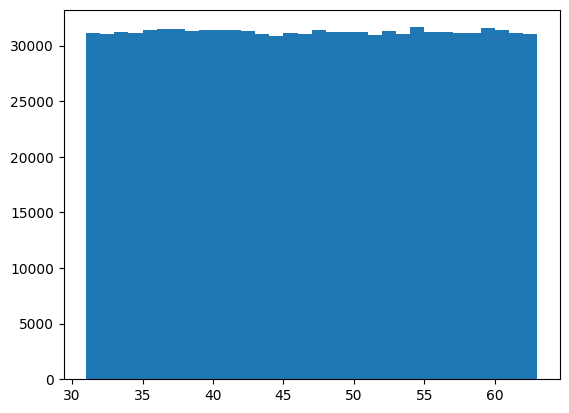

In [37]:


i0=None
i1= 19
i2= None

layer0_selected = np.bool(A0[i0]) if i0 is not None else np.ones(N_TRAIN, dtype=bool)
layer1_selected = np.bool(A1[i1]) if i1 is not None else np.ones(N_TRAIN, dtype=bool)
layer2_selected = np.bool(A2[i2]) if i2 is not None else np.ones(N_TRAIN, dtype=bool)

plt.hist(leaf_ids[layer0_selected*layer1_selected*layer2_selected], bins=np.arange(31,64))

In [33]:
layer0 = range(HIDDEN_DIMS[0])
layer1 = range(HIDDEN_DIMS[1])
layer2 = range(HIDDEN_DIMS[2])

for path in product([0],layer1,layer2):
    if path not in strong_paths:
        continue
    print(path,"\t",path_stats[path]["num_points"],"\t",path_stats[path]["weight"],
                "\t",path_stats[path]["acts_hist"][-3])


(0, 1, 0) 	 499195 	 0.32060534 	 31366
(0, 1, 1) 	 499577 	 0.20821024 	 31367
(0, 1, 2) 	 434682 	 0.45542413 	 26988
(0, 1, 3) 	 498878 	 0.27411437 	 31365
(0, 1, 4) 	 490225 	 0.24499556 	 30842
(0, 1, 5) 	 499172 	 0.20382342 	 31361
(0, 1, 6) 	 483289 	 0.30347332 	 31264
(0, 1, 7) 	 485395 	 0.32739043 	 30412
(0, 1, 8) 	 435357 	 0.3821716 	 31125
(0, 1, 9) 	 499420 	 0.39660874 	 31367
(0, 1, 10) 	 498214 	 0.30226493 	 31361
(0, 1, 12) 	 496923 	 0.22790547 	 31114
(0, 1, 13) 	 497751 	 0.30254826 	 31368
(0, 1, 14) 	 411107 	 0.5023231 	 31187
(0, 1, 15) 	 491911 	 0.19778357 	 31191
(0, 1, 16) 	 498585 	 0.1931189 	 31342
(0, 1, 17) 	 486825 	 0.2952462 	 31323
(0, 1, 18) 	 486969 	 0.37122777 	 31329
(0, 1, 19) 	 418453 	 0.9387883 	 30988
(0, 1, 20) 	 455432 	 0.33275947 	 22071
(0, 1, 22) 	 499108 	 0.28552765 	 31356
(0, 1, 23) 	 498869 	 0.21952373 	 31340
(0, 1, 24) 	 490615 	 0.21596918 	 30959
(0, 1, 25) 	 497394 	 0.24074665 	 31243
(0, 1, 26) 	 496725 	 0.3506691

In [91]:
np.linalg.norm(path_stats[path]["first_layer_gating_vec"])

np.float32(1.2154673)

<BarContainer object of 32 artists>

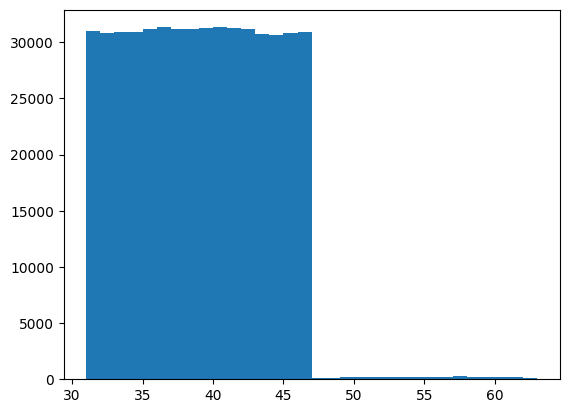

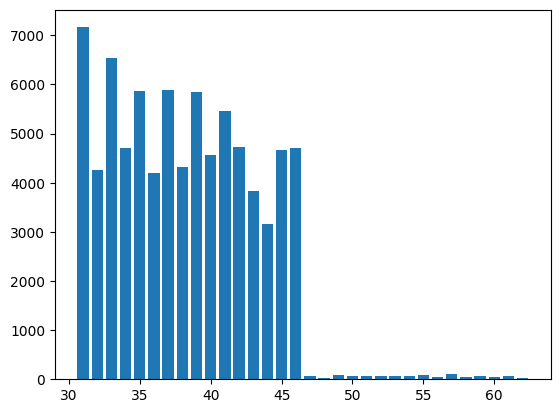

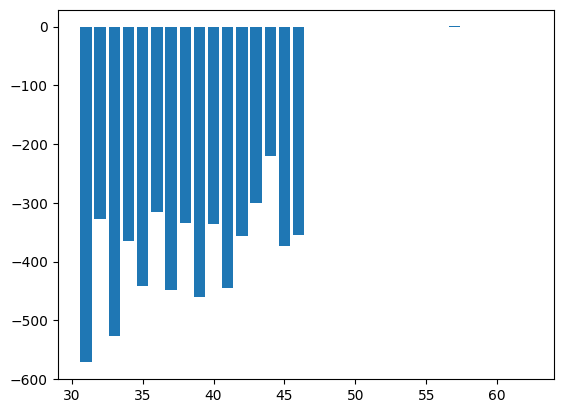

In [165]:
ACTIVITY_LAYER_IDX = 0
ACTIVITY_NEURON_ID =30
internal_node_count = tree.w_list.shape[0]
leaf_bins = np.arange(internal_node_count, 2 * internal_node_count + 2)

plt.hist(
    leaf_ids[acts[ACTIVITY_LAYER_IDX, ACTIVITY_NEURON_ID]],
    bins=leaf_bins,
);


residue_weighted_activations = acts[ACTIVITY_LAYER_IDX, ACTIVITY_NEURON_ID] * residues
residue_weighted_activations_leafwise = []

for j in sorted(set(leaf_ids)):
    residue_weighted_activations_leafwise.append(residue_weighted_activations[leaf_ids==j].sum())
plt.figure()
plt.bar(sorted(set(leaf_ids)),residue_weighted_activations_leafwise)

odt_node_focus = 0
residue_weighted_activations_odt_node_focus_component = residue_weighted_activations * (seed_result["data"]["x_train"]@tree.w_list[odt_node_focus])
residue_weighted_activations_odt_node_focus_component_leafwise = []
for j in sorted(set(leaf_ids)):
    residue_weighted_activations_odt_node_focus_component_leafwise.append(residue_weighted_activations_odt_node_focus_component[leaf_ids==j].sum())
plt.figure()
plt.bar(sorted(set(leaf_ids)),residue_weighted_activations_odt_node_focus_component_leafwise)


In [170]:
from layer_lenses.relu_analysis import first_layer_neuron_weighted_lens

FIRST_LAYER_NEURON_ID = 30
state = ckpts[EPOCH]
checkpoint_model = checkpoint_model_from_state(
    seed_result["out"]["model"],
    state,
)
acts = activation_tensor_by_layer_neuron_data(
    model=checkpoint_model,
    
    x_eval=seed_result["data"]["x_train"],
)

# Sum every active path from this first-layer neuron to the output.
total_lens = first_layer_neuron_weighted_lens(
    state_dict=state,
    activation_tensor=acts,
    first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
)
total_lens *= residues * -labels
grad_alt = (
    total_lens @ seed_result["data"]["x_train"] / len(residues)
)

# This should match the log-loss gradient for the selected first-layer neuron.
grad_check = log_loss_gradients(
    model=checkpoint_model,
    x=seed_result["data"]["x_train"],
    y=seed_result["data"]["y_train"],
)
true_grad = grad_check["hidden_layers.0.weight"][
    FIRST_LAYER_NEURON_ID
].numpy()


In [171]:
true_grad@grad_alt/(np.linalg.norm(true_grad)*np.linalg.norm(grad_alt))

np.float64(1.0000000278435082)

In [172]:
for j in range(0,31):
    print(j,true_grad@odt_wts[j].numpy()/(np.linalg.norm(true_grad)*np.linalg.norm(odt_wts[j])))

0 -0.5230474
1 -0.44689307
2 0.058224007
3 -0.16112305
4 0.022125661
5 -0.026853774
6 -0.22224987
7 -0.15297195
8 0.020571657
9 -0.06039109
10 -0.08045357
11 -0.09301743
12 -0.14372548
13 0.006397453
14 0.09984898
15 0.010756597
16 0.00016614622
17 -0.025858868
18 0.042909596
19 -0.05291578
20 -0.010228247
21 0.10732605
22 0.012547096
23 0.048583813
24 0.08698645
25 -0.070743546
26 -0.025504699
27 -0.047902264
28 -0.11950286
29 -0.07363838
30 0.07768927


In [169]:
for j in range(31,63):
    print(j,total_lens[leaf_ids==j].sum())


31 314378.03
32 -214477.02
33 289013.66
34 -233413.34
35 244261.23
36 -200535.28
37 245876.1
38 -206671.78
39 99599.42
40 -110208.4
41 92203.766
42 -115742.18
43 35998.617
44 -47606.113
45 49371.66
46 -55714.023
47 14368.966
48 -6819.907
49 20574.9
50 -12394.746
51 19117.83
52 -7075.673
53 17439.146
54 -9254.345
55 24475.371
56 -7916.5654
57 34179.72
58 -6561.244
59 20080.178
60 -8888.842
61 18572.844
62 -5716.2188


In [ ]:
from tqdm.std import tqdm

# Decompose the first-layer neuron's lens through one downstream hidden layer.
# A one-hidden-layer model has no downstream hidden layer, so its selected
# first-layer neuron is the sole component.
FIRST_LAYER_NEURON_ID = 30
PATH_LAYER_IDX = 1 if len(HIDDEN_DIMS) > 1 else 0
PATH_NODE_IDS = (
    range(HIDDEN_DIMS[PATH_LAYER_IDX])
    if PATH_LAYER_IDX > 0
    else [FIRST_LAYER_NEURON_ID]
)
NUM_GRAD_EPOCHS = 100
analysis_epochs = sorted(ckpts)[-NUM_GRAD_EPOCHS:]
internal_node_count = tree.w_list.shape[0]

for curr_path_node in PATH_NODE_IDS:
    path_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
    path_node_mask[PATH_LAYER_IDX][:] = False
    path_node_mask[PATH_LAYER_IDX][curr_path_node] = True

    true_grad_dict = {}
    grad_alt_dict = {}
    W0_dict = {}
    for epoch in tqdm(analysis_epochs):
        state = ckpts[epoch]
        checkpoint_model = checkpoint_model_from_state(
            seed_result["out"]["model"],
            state,
        )
        x_eval = seed_result["data"]["x_eval"]
        labels = seed_result["data"]["y_eval"]
        outputs = checkpoint_model(
            torch.tensor(x_eval, dtype=torch.float32)
        ).detach().cpu().numpy()
        residues = np.exp(-labels * outputs) / (1 + np.exp(-labels * outputs))
        residues = (residues + 1000.0) / 2000.0

        acts = activation_tensor_by_layer_neuron_data(
            model=checkpoint_model,
            x_eval=x_eval,
        )
        total_lens = first_layer_neuron_weighted_lens(
            state_dict=state,
            activation_tensor=acts,
            first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
            node_mask=path_node_mask,
        )
        total_lens *= residues * -labels
        grad_alt = total_lens @ x_eval / len(residues)

        grad_check = log_loss_gradients(
            model=checkpoint_model,
            x=x_eval,
            y=labels,
        )
        true_grad = grad_check["hidden_layers.0.weight"][
            FIRST_LAYER_NEURON_ID
        ].numpy()
        true_grad_dict[epoch] = true_grad
        grad_alt_dict[epoch] = grad_alt
        W0_dict[epoch] = state["hidden_layers.0.weight"][
            FIRST_LAYER_NEURON_ID
        ].numpy()

    true_grad_comps = {}
    alt_grad_comps = {}
    true_grad_comps_numpy = np.zeros(
        (len(true_grad_dict), internal_node_count)
    )
    alt_grad_comps_numpy = np.zeros(
        (len(grad_alt_dict), internal_node_count)
    )
    for row_idx, epoch in enumerate(analysis_epochs):
        true_grad_comps[epoch] = odt_wts.numpy() @ true_grad_dict[epoch]
        true_grad_comps_numpy[row_idx] = true_grad_comps[epoch]
        alt_grad_comps[epoch] = odt_wts.numpy() @ grad_alt_dict[epoch]
        alt_grad_comps_numpy[row_idx] = alt_grad_comps[epoch]

    for odt_node_idx in range(internal_node_count - 1):
        plt.plot(analysis_epochs, alt_grad_comps_numpy[:, odt_node_idx])
    plt.axhline(0.0, color="gray", linewidth=1)
    plt.plot(
        analysis_epochs,
        alt_grad_comps_numpy[:, -1],
        "r--",
    )
    plt.title(
        f"Through node {curr_path_node} in hidden layer {PATH_LAYER_IDX + 1}"
    )
    plt.show()


In [ ]:
from tqdm.std import tqdm

FIRST_LAYER_NEURON_ID = min(30, HIDDEN_DIMS[0] - 1)
PATH_LAYER_IDX = 1 if len(HIDDEN_DIMS) > 1 else 0
SELECTED_PATH_NODE_IDS = (
    [min(34, HIDDEN_DIMS[PATH_LAYER_IDX] - 1)]
    if PATH_LAYER_IDX > 0
    else [FIRST_LAYER_NEURON_ID]
)
NUM_GRAD_EPOCHS = 100
analysis_epochs = sorted(ckpts)[-NUM_GRAD_EPOCHS:]
internal_node_count = tree.w_list.shape[0]

path_node_mask = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]
path_node_mask[PATH_LAYER_IDX][:] = False
path_node_mask[PATH_LAYER_IDX][SELECTED_PATH_NODE_IDS] = True

true_grad_dict = {}
grad_alt_dict = {}
W0_dict = {}
for epoch in tqdm(analysis_epochs):
    state = ckpts[epoch]
    checkpoint_model = checkpoint_model_from_state(
        seed_result["out"]["model"],
        state,
    )
    x_eval = seed_result["data"]["x_eval"]
    labels = seed_result["data"]["y_eval"]
    outputs = checkpoint_model(
        torch.tensor(x_eval, dtype=torch.float32)
    ).detach().cpu().numpy()
    residues = np.exp(-labels * outputs) / (1 + np.exp(-labels * outputs))
    residues = (residues + 1000.0) / 2000.0

    acts = activation_tensor_by_layer_neuron_data(
        model=checkpoint_model,
        x_eval=x_eval,
    )
    total_lens = first_layer_neuron_weighted_lens(
        state_dict=state,
        activation_tensor=acts,
        first_layer_neuron_id=FIRST_LAYER_NEURON_ID,
        node_mask=path_node_mask,
    )
    total_lens *= residues * -labels
    grad_alt = total_lens @ x_eval / len(residues)

    grad_check = log_loss_gradients(
        model=checkpoint_model,
        x=x_eval,
        y=labels,
    )
    true_grad = grad_check["hidden_layers.0.weight"][
        FIRST_LAYER_NEURON_ID
    ].numpy()
    true_grad_dict[epoch] = true_grad
    grad_alt_dict[epoch] = grad_alt
    W0_dict[epoch] = state["hidden_layers.0.weight"][
        FIRST_LAYER_NEURON_ID
    ].numpy()

true_grad_comps = {}
alt_grad_comps = {}
true_grad_comps_numpy = np.zeros(
    (len(true_grad_dict), internal_node_count)
)
alt_grad_comps_numpy = np.zeros(
    (len(grad_alt_dict), internal_node_count)
)
for row_idx, epoch in enumerate(analysis_epochs):
    true_grad_comps[epoch] = odt_wts.numpy() @ true_grad_dict[epoch]
    true_grad_comps_numpy[row_idx] = true_grad_comps[epoch]
    alt_grad_comps[epoch] = odt_wts.numpy() @ grad_alt_dict[epoch]
    alt_grad_comps_numpy[row_idx] = alt_grad_comps[epoch]


In [ ]:
PLOT_ODT_NODE_IDS = [
    node_idx
    for node_idx in [0, 2, 5]
    if node_idx < internal_node_count
]
for odt_node_idx in PLOT_ODT_NODE_IDS:
    plt.plot(
        analysis_epochs,
        alt_grad_comps_numpy[:, odt_node_idx],
    )
plt.axhline(0.0, color="gray", linewidth=1)
plt.plot(
    analysis_epochs,
    alt_grad_comps_numpy[:, -1],
    "r--",
)
plt.show()


In [ ]:
comparison_epoch = analysis_epochs[0]
true_grad_dict[comparison_epoch] / grad_alt_dict[comparison_epoch]

In [ ]:
gradient_epochs = sorted(grad_alt_dict)
internal_node_count = tree.w_list.shape[0]
true_grad_comps = {}
alt_grad_comps = {}
true_grad_comps_numpy = np.zeros(
    (len(gradient_epochs), internal_node_count)
)
alt_grad_comps_numpy = np.zeros(
    (len(gradient_epochs), internal_node_count)
)
for row_idx, epoch in enumerate(gradient_epochs):
    true_grad_comps[epoch] = odt_wts.numpy() @ true_grad_dict[epoch]
    true_grad_comps_numpy[row_idx] = true_grad_comps[epoch]
    alt_grad_comps[epoch] = odt_wts.numpy() @ grad_alt_dict[epoch]
    alt_grad_comps_numpy[row_idx] = alt_grad_comps[epoch]


In [ ]:
# All selected paths through FIRST_LAYER_NEURON_ID.
for odt_node_idx in range(internal_node_count - 1):
    plt.plot(
        gradient_epochs,
        alt_grad_comps_numpy[:, odt_node_idx],
    )
plt.axhline(0.0, color="gray", linewidth=1)
plt.plot(
    gradient_epochs,
    alt_grad_comps_numpy[:, -1],
    "r--",
)
plt.show()

In [ ]:
plt.plot(true_grad_comps.keys(),true_grad_comps_numpy[:,0] )
plt.plot(alt_grad_comps.keys(),alt_grad_comps_numpy[:,0] )
plt.plot([min(true_grad_comps.keys()),max(true_grad_comps.keys())],[0,0])

In [ ]:
grad_epochs = sorted(grad_comps)
PLOT_GRAD_ODT_NODE_IDS = [
    node_idx
    for node_idx in [0, 2, 6, 14, internal_node_count - 1]
    if 0 <= node_idx < internal_node_count
]
for odt_node_idx in dict.fromkeys(PLOT_GRAD_ODT_NODE_IDS):
    plt.plot(
        grad_epochs,
        grad_comps_numpy[:, odt_node_idx],
        label=f"ODT node {odt_node_idx}",
    )
plt.axhline(0.0, color="gray", linewidth=1)
plt.legend()

In [ ]:
CUMULATIVE_ODT_NODE_IDS = [
    node_idx
    for node_idx in [0, 1, 2, internal_node_count - 1]
    if 0 <= node_idx < internal_node_count
]
for odt_node_idx in dict.fromkeys(CUMULATIVE_ODT_NODE_IDS):
    plt.plot(
        np.cumsum(grad_comps_numpy[:, odt_node_idx]),
        label=f"ODT node {odt_node_idx}",
    )
plt.axhline(0.0, color="gray", linewidth=1)
plt.legend()

In [ ]:
W0_epochs = sorted(W0_dict)
internal_node_count = tree.w_list.shape[0]
W0_comps = {}
W0_comps_numpy = np.zeros((len(W0_epochs), internal_node_count))
for row_idx, epoch in enumerate(W0_epochs):
    W0_comps[epoch] = odt_wts.numpy() @ W0_dict[epoch]
    W0_comps_numpy[row_idx] = W0_comps[epoch]


In [ ]:
PLOT_ODT_NODE_IDS = [
    node_idx
    for node_idx in [0, 2, 6, 14, 30, 24]
    if node_idx < internal_node_count
]
for odt_node_idx in PLOT_ODT_NODE_IDS:
    plt.plot(
        W0_epochs,
        W0_comps_numpy[:, odt_node_idx],
        label=f"ODT node {odt_node_idx}",
    )
plt.axhline(0.0, color="gray", linewidth=1)
plt.legend()

In [ ]:
print(np.max(np.abs(odt_wts.numpy()@grad_alt)))
print(np.argmax(np.abs(odt_wts.numpy()@grad_alt)))
print(odt_wts.numpy()@grad_alt)
print(odt_wts.numpy()@true_grad)

In [ ]:
ODT_NODE_ID = min(30, tree.w_list.shape[0] - 1)
first_layer_weight = HIDDEN_WEIGHTS[0][FIRST_LAYER_NEURON_ID]
(
    first_layer_weight @ odt_wts[ODT_NODE_ID]
    / (
        torch.norm(first_layer_weight)
        * torch.norm(odt_wts[ODT_NODE_ID])
    )
)

In [ ]:
u_ODT_node = seed_result["tree"].w_list[ODT_NODE_ID]
grad_alt_cosine = grad_alt @ u_ODT_node / (
    np.linalg.norm(u_ODT_node) * np.linalg.norm(grad_alt)
)
print(
    "Cosine similarity between grad_alt for first-layer neuron",
    FIRST_LAYER_NEURON_ID,
    "and ODT node",
    ODT_NODE_ID,
    "at epoch",
    EPOCH,
    ":",
    grad_alt_cosine,
)
print("Norm of grad_alt:", np.linalg.norm(grad_alt))

In [ ]:
from layer_lenses.relu_analysis import summarize_neuron_leaf_activity

checkpoint_model = checkpoint_model_from_state(seed_result["out"]["model"], ckpts[EPOCH])

neuron_leaf_activity_summary = summarize_neuron_leaf_activity(
    model=checkpoint_model,
    x_eval=seed_result["data"]["x_eval"],
    tree=seed_result["tree"],
)

# display(neuron_leaf_activity_summary)
# show(
#     neuron_leaf_activity_summary,
#     scrollY="500px",
#     scrollX=True,
#     search=True,
#     paging=True,
#     pageLength=25,
# )

In [ ]:
# Build: neuron -> activity vector over ODT leaves
# Input: neuron_leaf_activity_summary (DataFrame from earlier cell)
# Output: neuron_to_leaf_activity (dict)

from layer_lenses.relu_analysis import neuron_leaf_activity_dict

neuron_to_leaf_activity, neuron_activity_leaf_order = neuron_leaf_activity_dict(
    neuron_leaf_activity_summary,
    key_mode="layer_local",
)

print(f"Built dictionary for {len(neuron_to_leaf_activity)} neurons.")
print(f"Vector length per neuron: {len(neuron_activity_leaf_order)} leaves")
print("Example key:", next(iter(neuron_to_leaf_activity)))
print("Example vector:", neuron_to_leaf_activity[next(iter(neuron_to_leaf_activity))])

In [ ]:
EXAMPLE_ACTIVITY_LAYER_IDX = min(1, len(HIDDEN_DIMS) - 1)
EXAMPLE_ACTIVITY_NEURON_ID = min(
    7,
    HIDDEN_DIMS[EXAMPLE_ACTIVITY_LAYER_IDX] - 1,
)
neuron_to_leaf_activity[
    (EXAMPLE_ACTIVITY_LAYER_IDX, EXAMPLE_ACTIVITY_NEURON_ID)
]

## Start/end metrics

This block computes start/end metrics for the selected seed.

In [25]:
if seed_result is None:
    raise ValueError("Run the training cell first to populate seed_result.")

rows = collect_start_end_metrics(seed_result)
metrics_table = pd.DataFrame(rows).sort_values(["timepoint"]).reset_index(drop=True)
display(metrics_table)

,timepoint,epoch,train_log_loss,test_error
0,end,995100,0.063215,0.024157
1,start,0,0.693162,0.500519


## Quick visualization

Bar plots for start vs end test error and train log loss for the selected seed.

In [ ]:
if seed_result is None:
    raise ValueError("Run the training cell first to populate seed_result.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(metrics_table["timepoint"], metrics_table["test_error"])
axes[0].set_title("Test error")

axes[1].bar(metrics_table["timepoint"], metrics_table["train_log_loss"])
axes[1].set_title("Train log loss")

plt.tight_layout()
plt.show()